# 1046. Last Stone Weight
**Difficulty:** 🟢 Easy · **Topic:** Heap · **Pattern:** [Heap Simulation](README.md) · **LeetCode:** https://leetcode.com/problems/last-stone-weight/

## 💡 Concepts

**Core concept(s):** **Heap simulation** — run the process the statement describes, round by round, and let a **max-heap** answer "which items are the biggest right now?" in `O(log n)` instead of re-sorting.

**Why it applies here:**
- Every round needs the **two heaviest** stones *of the current pile*.
- The pile changes every round: two stones leave, and sometimes one new (smaller) stone comes back.
- "Repeatedly take the largest, then put something back" is exactly what a priority queue is built for.

**Key intuition:**
- There is no clever shortcut: the answer is whatever the smashing process leaves behind, so we simulate it.
- The only cost worth optimising is *finding the two heaviest each round*.
- Sorting the whole pile every round answers it, but redoes work. A heap keeps the pile "partly sorted" so each round costs only `O(log n)`.

---

### 📚 What is a Heap / Priority Queue?
- A **priority queue** is a collection where you always take out the **most important** item next (the smallest or the largest), no matter the order items went in.
- A **binary heap** implements it as a complete binary tree stored in a plain list: the item at index `i` has children at `2i+1` and `2i+2`.
- **Heap property (min-heap):** every parent is `<=` its children, so the smallest item is always at index `0`.
- **Key operations:** peek the top `heap[0]` **O(1)**; push / pop **O(log n)** (the item bubbles up or sinks down one level at a time); build from a list with `heapify` **O(n)**.
- **In Python:** the `heapq` module works on a plain `list` and is a **min-heap only**.
- **Max-heap trick:** store **negated** values (`-s`). The smallest negative is the largest stone, so `-heapq.heappop(h)` returns the heaviest. Negate again when you push.

### 📚 What is Sorting (as used in the brute force)?
- **Sorting** puts the whole list in order; after `stones.sort()` the two heaviest are the last two items.
- **Cost:** `O(k log k)` for a list of `k` items in general.
- **In Python:** `list.sort()` uses **Timsort**, which detects already-sorted runs. That detail matters in the benchmark below.

### 📚 What is a Simulation?
- A **simulation** follows the rules of the statement literally, step by step, until the process stops.
- It is the right tool when the statement *defines* the answer as the outcome of a process and no formula is obvious.
- The data structure you pick decides how fast each step is.

---

**Prerequisite knowledge:**
- Python lists, `pop()` / `append()` at the end are `O(1)`.
- The heap idea itself is covered in depth in [Heaps & Priority Queues](../../../deep_dive/12_Heaps_Priority_Queues/README.md).

## 📝 Problem

You have a list of stone weights. Each turn, take the **two heaviest** stones `y >= x` and smash them together:
- if `x == y`, both stones are destroyed;
- if `x != y`, the stone of weight `x` is destroyed and the other becomes `y - x`.

When at most one stone is left, return its weight, or `0` if none remain.

**Example 1**
```
stones = [2,7,4,1,8,1]  ->  1

smash 8 and 7 -> 1       pile [2,4,1,1,1]
smash 4 and 2 -> 2       pile [2,1,1,1]
smash 2 and 1 -> 1       pile [1,1,1]
smash 1 and 1 -> both gone, pile [1]   -> answer 1
```

**Example 2**
```
stones = [1]  ->  1   (nothing to smash)
```

**Constraints:** `1 <= stones.length <= 30`, `1 <= stones[i] <= 1000`.

> Only two meaningfully different approaches exist: re-sort the pile every round, or keep it in a max-heap. (Both simulate the same process; they differ only in how they find the two heaviest.)

In [1]:
import heapq
import random
from typing import List

### Approach 1 — Brute Force: re-sort the pile every round

**Idea:**
1. Copy the stones into a list (so the caller's list is not changed).
2. While two or more stones remain: sort the list, so the two heaviest are at the end.
3. Pop `y` (heaviest) and `x` (second heaviest). If they differ, append the leftover `y - x`.
4. Return the last stone, or `0` if the pile is empty.

**Time complexity:** `O(n² log n)` as written — up to `n - 1` rounds, each with a full sort of up to `n` stones. In CPython it is closer to `O(n²)`: after the first round the list is already sorted except for the one stone appended at the end, and Timsort finishes such a list in about linear time. The benchmark below shows that ≈4× growth per doubling.

**Space complexity:** `O(n)` — the copy of the pile (Timsort may also use up to `O(n)` scratch space).

In [2]:
def last_stone_weight_sort(stones: List[int]) -> int:
    pile = list(stones)                    # work on a copy, never mutate the input
    while len(pile) > 1:
        pile.sort()                        # re-sort every round: heaviest two end up last
        y = pile.pop()                     # heaviest
        x = pile.pop()                     # second heaviest (x <= y)
        if y != x:
            pile.append(y - x)             # the leftover joins the pile, unsorted
    return pile[0] if pile else 0

### Approach 2 — Max-heap simulation (optimal · pattern template)

**Idea:** the [Heap Simulation](README.md) template: put everything in a max-heap, then loop "pop the best, act, push back what is left".
1. Negate every weight and `heapify` the list: `heapq` is a min-heap, so the most negative value (= heaviest stone) sits at index `0`.
2. While the heap holds two or more stones: pop twice to get `y` and `x` (undo the negation).
3. If `y != x`, push `-(y - x)` back: the leftover is a new stone that competes in later rounds.
4. Return `-heap[0]` if a stone is left, else `0`.

**Time complexity:** `O(n log n)` — `heapify` is `O(n)`; each of the at most `n - 1` rounds does two pops and at most one push, `O(log n)` each.

**Space complexity:** `O(n)` — the heap holds at most `n` stones.

In [3]:
def last_stone_weight_heap(stones: List[int]) -> int:
    heap = [-s for s in stones]            # negate: heapq is a min-heap, we need the max
    heapq.heapify(heap)                    # O(n) build; heap[0] = -(heaviest)
    while len(heap) > 1:
        y = -heapq.heappop(heap)           # heaviest
        x = -heapq.heappop(heap)           # second heaviest
        if y != x:
            heapq.heappush(heap, -(y - x)) # leftover goes back in: it may be the max later
    return -heap[0] if heap else 0

In [4]:
# Correctness check
tests = [
    ([2, 7, 4, 1, 8, 1], 1),   # LeetCode example 1
    ([1],                1),   # LeetCode example 2: nothing to smash
    ([2, 2],             0),   # equal pair: both destroyed, empty pile -> 0
    ([10, 4],            6),   # one smash leaves 6
    ([3, 3, 3],          3),   # 3 and 3 vanish, the third 3 survives
    ([1, 1, 1, 1],       0),   # pairs cancel completely
]
for stones, exp in tests:
    a, b = last_stone_weight_sort(stones), last_stone_weight_heap(stones)
    print(f"{str(stones):22} -> {b}")
    assert a == b == exp, f"mismatch on {stones}: sort={a} heap={b} expected={exp}"

# Randomised cross-check: both approaches must agree, and must not change the input
rng = random.Random(1046)
for _ in range(500):
    stones = [rng.randint(1, 1000) for _ in range(rng.randint(1, 30))]
    before = list(stones)
    assert last_stone_weight_sort(stones) == last_stone_weight_heap(stones), stones
    assert stones == before, "input list was mutated"
print("500 random piles: both approaches agree")

print("\nAll tests passed")

[2, 7, 4, 1, 8, 1]     -> 1
[1]                    -> 1
[2, 2]                 -> 0
[10, 4]                -> 6
[3, 3, 3]              -> 3
[1, 1, 1, 1]           -> 0
500 random piles: both approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on piles of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)` / `O(n log n)` | ≈ **2×** (a little over 2× for `n log n`) |
| `O(n²)`               | ≈ **4×** |
| `O(n² log n)`         | a little over **4×** |

The worst case needs many rounds, so the input is `n` **shuffled random weights** up to `10⁶`: equal pairs (which remove two stones at once) are rare, so there are close to `n - 1` rounds. The values go beyond LeetCode's limits on purpose, to make the growth visible.


sort every round O(n^2 log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       0.95 |           n/a
     2000 |       3.61 |         3.82x
     4000 |      14.80 |         4.10x
     8000 |      60.33 |         4.08x

max-heap O(n log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       0.28 |           n/a
     2000 |       0.53 |         1.88x
     4000 |       1.07 |         2.00x
     8000 |       2.38 |         2.23x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


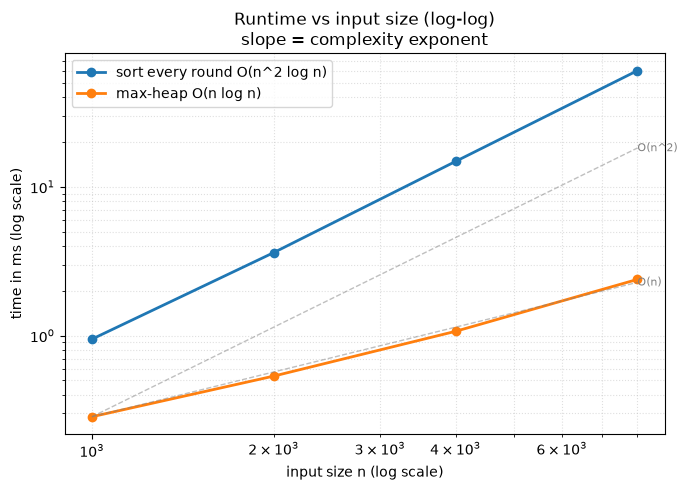

{'sort every round O(n^2 log n)': [0.9455420076847076,
  3.6108330823481083,
  14.803333906456828,
  60.33066695090383],
 'max-heap O(n log n)': [0.2846659626811743,
  0.5339999916031957,
  1.0677080135792494,
  2.3844169918447733]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    rng = random.Random(n)
    return ([rng.randint(1, 10**6) for _ in range(n)],)   # shuffled, few equal pairs -> ~n rounds
solutions = {
    "sort every round O(n^2 log n)": last_stone_weight_sort,
    "max-heap O(n log n)": last_stone_weight_heap,
}
sizes = [1000, 2000, 4000, 8000]

benchmark(solutions, make_worst_case, sizes, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Heap Simulation](README.md) — the statement defines the answer as the result of a process; a max-heap hands out the two heaviest stones each round and takes the leftover back.
- **Heap simulation loop:** `heapify` once → `while` work remains: pop the best item(s), apply one step of the rules, push back whatever is left. Each round costs `O(log n)` instead of a full re-sort.
- **Max-heap in Python:** `heapq` is a min-heap; negate on the way in (`-s`) and on the way out (`-heappop(h)`).
- **Signal:** "each turn, take the largest / smallest", "repeat until one is left", "combine the two biggest", a pile that changes after every step.
- **Related problems:** Task Scheduler (max-heap + cooldown queue, next in this pattern), Reorganize String, Minimum Cost to Connect Sticks (min-heap version), Kth Largest Element in an Array.
- **Common pitfalls:**
  1. Forgetting to negate on push as well as on pop — the leftover then sinks to the wrong place.
  2. Sorting once at the start and assuming the order holds: the leftover `y - x` can land anywhere in the order.
  3. Returning `heap[0]` instead of `-heap[0]`, or crashing on an empty heap instead of returning `0`.
  4. Mutating the caller's list (sorting it in place) when the function should be side-effect free.